# Indian House Price Analysis and Prediction



## Step 1: Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

import joblib

print("Libraries imported successfully")

Libraries imported successfully


**Inference:** We imported the tools needed to load data, create charts, prepare features, train models, and evaluate predictions.

## Step 2: Load each city dataset

In [2]:
bangalore = pd.read_csv(r"C:\Users\manik\Downloads\INDIAN HOUSE PRICE DATASET\Bangalore.csv")
chennai = pd.read_csv(r"C:\Users\manik\Downloads\INDIAN HOUSE PRICE DATASET\Chennai.csv")
delhi = pd.read_csv(r"C:\Users\manik\Downloads\INDIAN HOUSE PRICE DATASET\Delhi.csv")
hyderabad = pd.read_csv(r"C:\Users\manik\Downloads\INDIAN HOUSE PRICE DATASET\Hyderabad.csv")
kolkata = pd.read_csv(r"C:\Users\manik\Downloads\INDIAN HOUSE PRICE DATASET\Kolkata.csv")
mumbai = pd.read_csv(r"C:\Users\manik\Downloads\INDIAN HOUSE PRICE DATASET\Mumbai.csv")

print("All datasets loaded successfully.")



hyderabad["city"] = "Hyderabad"
bangalore["city"] = "Bangalore"
kolkata["city"] = "Kolkata"
delhi["city"] = "Delhi"
mumbai["city"] = "Mumbai"
chennai["city"] = "Chennai"

print("Hyderabad:", hyderabad.shape)
print("Bangalore:", bangalore.shape)
print("Kolkata:", kolkata.shape)
print("Delhi:", delhi.shape)
print("Mumbai:", mumbai.shape)
print("Chennai:", chennai.shape)

All datasets loaded successfully.
Hyderabad: (2518, 41)
Bangalore: (6207, 41)
Kolkata: (6507, 41)
Delhi: (4998, 41)
Mumbai: (7719, 41)
Chennai: (5014, 41)


**Inference:** These outputs show the number of rows and columns in each city's dataset.

## Step 3: Combine all six datasets

In [3]:
df = pd.concat(
    [hyderabad, bangalore, kolkata, delhi, mumbai, chennai],
    ignore_index=True
)

print("Combined dataset shape:", df.shape)
df.head()

Combined dataset shape: (32963, 41)


,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,...,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Stadium,city
0,6968000,1340,Nizampet,2,0,0,1,1,1,1,...,0,1,0,0,0,0,0,0,0,Hyderabad
1,29000000,3498,Hitech City,4,0,0,1,1,1,1,...,0,1,0,0,0,0,0,0,0,Hyderabad
2,6590000,1318,Manikonda,2,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,Hyderabad
3,5739000,1295,Alwal,3,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Hyderabad
4,5679000,1145,Kukatpally,2,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,Hyderabad


**Inference:** We now have one dataset containing house listings from all six cities. The `city` column identifies each listing's city.

## Step 4: View column names and data types

In [4]:
print(df.columns.tolist())
df.info()
df.describe()

['Price', 'Area', 'Location', 'No. of Bedrooms', 'Resale', 'MaintenanceStaff', 'Gymnasium', 'SwimmingPool', 'LandscapedGardens', 'JoggingTrack', 'RainWaterHarvesting', 'IndoorGames', 'ShoppingMall', 'Intercom', 'SportsFacility', 'ATM', 'ClubHouse', 'School', '24X7Security', 'PowerBackup', 'CarParking', 'StaffQuarter', 'Cafeteria', 'MultipurposeRoom', 'Hospital', 'WashingMachine', 'Gasconnection', 'AC', 'Wifi', "Children'splayarea", 'LiftAvailable', 'BED', 'VaastuCompliant', 'Microwave', 'GolfCourse', 'TV', 'DiningTable', 'Sofa', 'Wardrobe', 'Stadium', 'city']
<class 'pandas.DataFrame'>
RangeIndex: 32963 entries, 0 to 32962
Data columns (total 41 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Price                32963 non-null  int64
 1   Area                 32963 non-null  int64
 2   Location             32963 non-null  str  
 3   No. of Bedrooms      32963 non-null  int64
 4   Resale               32963 non-null  int64


,Price,Area,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,RainWaterHarvesting,...,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Stadium
count,3.296300e+04,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000,...,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000,32963.000000
mean,1.168672e+07,1293.362194,2.411765,0.381397,6.296454,6.403725,6.371325,6.351151,6.346328,6.356855,...,6.463671,6.272154,6.335497,6.259169,6.250887,6.261293,6.260413,6.259867,6.250675,6.260019
std,2.307368e+07,763.703754,0.812800,0.485737,4.075024,3.917995,3.966385,3.996086,4.003140,3.987722,...,3.826128,4.109373,4.018912,4.127551,4.139083,4.124586,4.125815,4.126577,4.139378,4.126365
min,2.000000e+06,200.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.071500e+06,853.000000,2.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,6.711000e+06,1125.000000,2.000000,0.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,...,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000
75%,1.200000e+07,1500.000000,3.000000,1.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,...,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000
max,8.546000e+08,16000.000000,9.000000,1.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,...,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000


**Inference:** Check that `Price`, `Area`, and `No. of Bedrooms` are present. The summary shows typical values and ranges for numerical columns.

## Step 5: Check missing values and duplicate rows

In [5]:
print("Missing values in each column:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:
Price                  0
Area                   0
Location               0
No. of Bedrooms        0
Resale                 0
MaintenanceStaff       0
Gymnasium              0
SwimmingPool           0
LandscapedGardens      0
JoggingTrack           0
RainWaterHarvesting    0
IndoorGames            0
ShoppingMall           0
Intercom               0
SportsFacility         0
ATM                    0
ClubHouse              0
School                 0
24X7Security           0
PowerBackup            0
CarParking             0
StaffQuarter           0
Cafeteria              0
MultipurposeRoom       0
Hospital               0
WashingMachine         0
Gasconnection          0
AC                     0
Wifi                   0
Children'splayarea     0
LiftAvailable          0
BED                    0
VaastuCompliant        0
Microwave              0
GolfCourse             0
TV                     0
DiningTable            0
Sofa                   0
Wardrobe           

**Inference:** Missing values may need filling, and duplicate rows should be removed so repeated listings are not counted more than once.

## Step 6: Remove duplicates and invalid key values

In [6]:
df = df.drop_duplicates()

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Area"] = pd.to_numeric(df["Area"], errors="coerce")
df["No. of Bedrooms"] = pd.to_numeric(df["No. of Bedrooms"], errors="coerce")

df = df.dropna(subset=["Price", "Area", "No. of Bedrooms"])
df = df[
    (df["Price"] > 0) &
    (df["Area"] > 0) &
    (df["No. of Bedrooms"] > 0)
]

print("Cleaned dataset shape:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Cleaned dataset shape: (29135, 41)
Duplicates remaining: 0


**Inference:** Exact duplicates and rows with missing or non-positive price, area, or bedroom count are removed. Other feature columns can still contain missing values.

## Step 7: Count listings in each city

city
Mumbai       6925
Kolkata      6275
Bangalore    5521
Chennai      4307
Delhi        4109
Hyderabad    1998
Name: count, dtype: int64


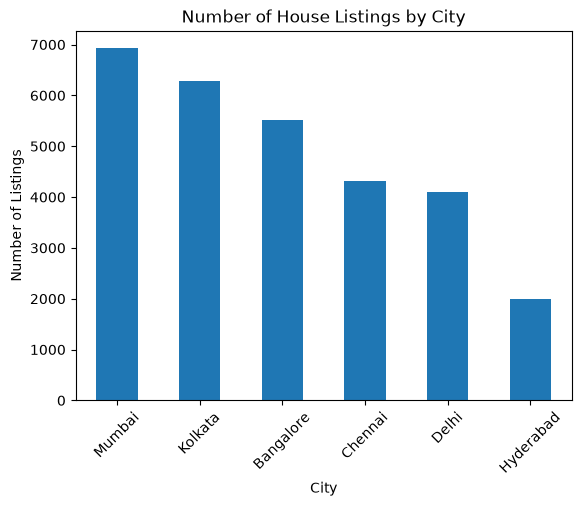

Most listings: Mumbai
Fewest listings: Hyderabad


In [7]:
city_counts = df["city"].value_counts()
print(city_counts)

city_counts.plot(kind="bar")
plt.title("Number of House Listings by City")
plt.xlabel("City")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45)
plt.show()

print("Most listings:", city_counts.idxmax())
print("Fewest listings:", city_counts.idxmin())

**Inference:** The printed city names show which city has the most and fewest listings in this dataset. This does not necessarily represent the entire city's housing market.

## Step 8: Understand the price distribution

count    2.913500e+04
mean     1.195267e+07
std      2.387647e+07
min      2.000000e+06
25%      4.179999e+06
50%      6.884999e+06
75%      1.230000e+07
max      8.546000e+08
Name: Price, dtype: float64


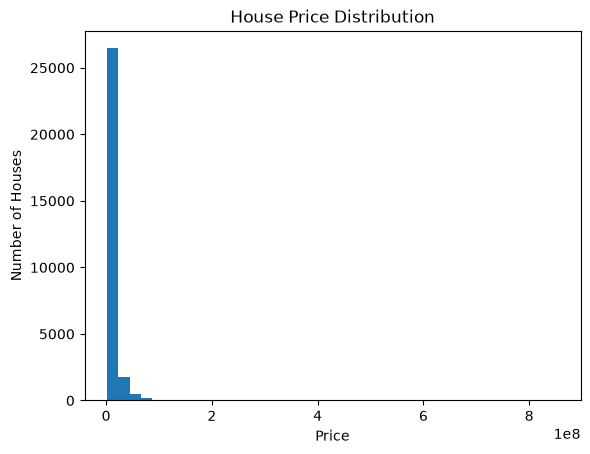

Mean price: 11952667.000034323
Median price: 6884999.0


In [8]:
print(df["Price"].describe())

plt.hist(df["Price"], bins=40)
plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Number of Houses")
plt.show()

print("Mean price:", df["Price"].mean())
print("Median price:", df["Price"].median())

**Inference:** The histogram shows how prices are distributed. If the mean is much higher than the median, some expensive properties may be pulling the mean upward.

## Step 9: Compare house prices by city

                   mean     median  count
city                                     
Mumbai     1.525685e+07  9500000.0   6925
Hyderabad  1.014127e+07  7873500.0   1998
Delhi      1.814434e+07  7800000.0   4109
Bangalore  1.080709e+07  7300000.0   5521
Chennai    8.933745e+06  5850000.0   4307
Kolkata    7.908581e+06  4923000.0   6275


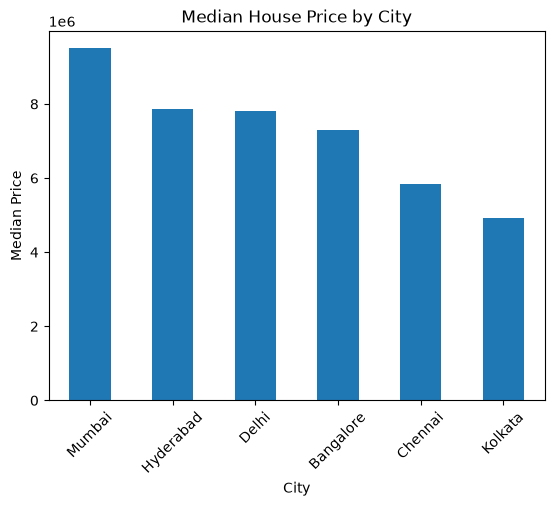

Highest median price city: Mumbai
Lowest median price city: Kolkata


In [9]:
city_prices = df.groupby("city")["Price"].agg(["mean", "median", "count"])
print(city_prices.sort_values("median", ascending=False))

city_prices["median"].sort_values(ascending=False).plot(kind="bar")
plt.title("Median House Price by City")
plt.xlabel("City")
plt.ylabel("Median Price")
plt.xticks(rotation=45)
plt.show()

print("Highest median price city:", city_prices["median"].idxmax())
print("Lowest median price city:", city_prices["median"].idxmin())

**Inference:** The median-price comparison shows which city has higher or lower typical listing prices in this dataset. Median is less affected by extreme prices than mean.

## Step 10: Check the relationship between area and price

Area-price correlation: 0.26895433902340155


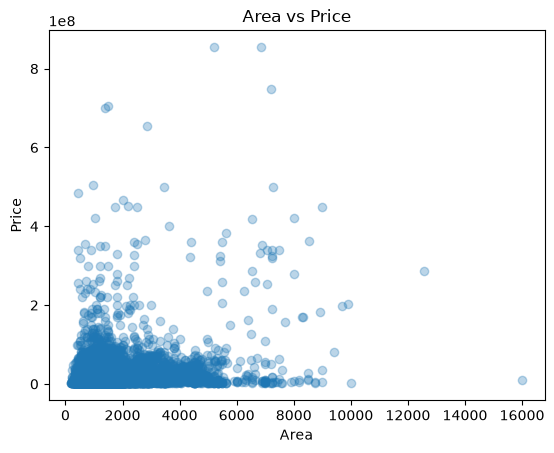

In [10]:
print("Area-price correlation:", df["Area"].corr(df["Price"]))

plt.scatter(df["Area"], df["Price"], alpha=0.3)
plt.title("Area vs Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

**Inference:** If the points generally rise as area increases and correlation is positive, larger homes tend to cost more in this dataset. Other factors also affect price.

## Step 11: Compare price by number of bedrooms

No. of Bedrooms
1     6000000.0
2     5900000.0
3     8000000.0
4    13350000.0
5    14650000.0
6    13400000.0
7    15750000.0
8    50000000.0
9     2400000.0
Name: Price, dtype: float64


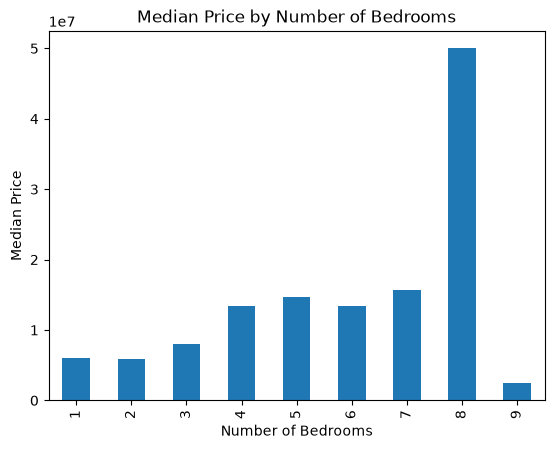

In [11]:
bedroom_prices = df.groupby("No. of Bedrooms")["Price"].median()
print(bedroom_prices)

bedroom_prices.plot(kind="bar")
plt.title("Median Price by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Median Price")
plt.show()

**Inference:** This shows how median price differs by bedroom count. More bedrooms do not guarantee a higher price because area and location also matter.

## Step 12: Compare resale status

In [12]:
if "Resale" in df.columns:
    print(df.groupby("Resale")["Price"].agg(["count", "mean", "median"]))
else:
    print("No Resale column in this dataset")

        count          mean     median
Resale                                
0       18150  1.066729e+07  6425500.0
1       10985  1.407644e+07  8013000.0


**Inference:** If the column exists, compare the median prices across resale categories. This is a comparison, not proof that resale status causes a price difference.

## Step 13: Prepare the target and input features

In [13]:
X = df.drop("Price", axis=1)
y = df["Price"]

print("Input data shape:", X.shape)
print("Target data shape:", y.shape)
print("Input columns:", X.columns.tolist())

Input data shape: (29135, 40)
Target data shape: (29135,)
Input columns: ['Area', 'Location', 'No. of Bedrooms', 'Resale', 'MaintenanceStaff', 'Gymnasium', 'SwimmingPool', 'LandscapedGardens', 'JoggingTrack', 'RainWaterHarvesting', 'IndoorGames', 'ShoppingMall', 'Intercom', 'SportsFacility', 'ATM', 'ClubHouse', 'School', '24X7Security', 'PowerBackup', 'CarParking', 'StaffQuarter', 'Cafeteria', 'MultipurposeRoom', 'Hospital', 'WashingMachine', 'Gasconnection', 'AC', 'Wifi', "Children'splayarea", 'LiftAvailable', 'BED', 'VaastuCompliant', 'Microwave', 'GolfCourse', 'TV', 'DiningTable', 'Sofa', 'Wardrobe', 'Stadium', 'city']


**Inference:** `X` contains the house details. `y` contains the price we want the model to predict.

## Step 14: Split data into training and testing sets

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 23308
Testing rows: 5827


**Inference:** The model learns from 80% of the data. The remaining 20% is held back to check predictions on unseen records.

## Step 15: Identify numerical and categorical columns

In [15]:
numeric_columns = X_train.select_dtypes(include=np.number).columns
categorical_columns = X_train.select_dtypes(exclude=np.number).columns

print("Numerical columns:", list(numeric_columns))
print("Categorical columns:", list(categorical_columns))

Numerical columns: ['Area', 'No. of Bedrooms', 'Resale', 'MaintenanceStaff', 'Gymnasium', 'SwimmingPool', 'LandscapedGardens', 'JoggingTrack', 'RainWaterHarvesting', 'IndoorGames', 'ShoppingMall', 'Intercom', 'SportsFacility', 'ATM', 'ClubHouse', 'School', '24X7Security', 'PowerBackup', 'CarParking', 'StaffQuarter', 'Cafeteria', 'MultipurposeRoom', 'Hospital', 'WashingMachine', 'Gasconnection', 'AC', 'Wifi', "Children'splayarea", 'LiftAvailable', 'BED', 'VaastuCompliant', 'Microwave', 'GolfCourse', 'TV', 'DiningTable', 'Sofa', 'Wardrobe', 'Stadium']
Categorical columns: ['Location', 'city']


**Inference:** Numerical columns contain numbers; categorical columns contain labels such as city or location. They need different preparation.

## Step 16: Prepare numerical and categorical columns

In [16]:
numeric_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

categorical_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numbers", numeric_steps, numeric_columns),
    ("categories", categorical_steps, categorical_columns)
])

print("Preprocessing is ready.")

Preprocessing is ready.


**Inference:** Missing numerical values are filled with the median and scaled. Missing categories are filled with the most frequent category and converted into numeric columns. This preparation is learned from training data when fitting the model.

## Step 17: Train Linear Regression

In [17]:
linear_model = Pipeline([
    ("prepare_data", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)
print("Linear Regression R2:", linear_r2)

Linear Regression MAE: 7574195.825088155
Linear Regression RMSE: 18680734.271509115
Linear Regression R2: 0.17564138692463205


**Inference:** These are Linear Regression's errors and R² score. Lower MAE/RMSE are better; R² closer to 1 is generally better.

## Step 18: Train Decision Tree

In [18]:
tree_model = Pipeline([
    ("prepare_data", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=15, min_samples_leaf=5, random_state=42
    ))
])

tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predictions))
tree_r2 = r2_score(y_test, tree_predictions)

print("Decision Tree MAE:", tree_mae)
print("Decision Tree RMSE:", tree_rmse)
print("Decision Tree R2:", tree_r2)

Decision Tree MAE: 7150551.119143081
Decision Tree RMSE: 19768928.70097297
Decision Tree R2: 0.07680261738664429


**Inference:** Compare these metrics with Linear Regression. Lower RMSE indicates fewer large prediction errors on this test set.

## Step 19: Train Random Forest

In [19]:
forest_model = Pipeline([
    ("prepare_data", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100, max_depth=20, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

print("Random Forest MAE:", forest_mae)
print("Random Forest RMSE:", forest_rmse)
print("Random Forest R2:", forest_r2)

Random Forest MAE: 6955108.127769231
Random Forest RMSE: 19467682.349333905
Random Forest R2: 0.10472429958482998


**Inference:** Compare Random Forest with the other models. Its test RMSE helps show whether it predicts better on this split.

## Step 20: Compare all three models

In [20]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [linear_mae, tree_mae, forest_mae],
    "RMSE": [linear_rmse, tree_rmse, forest_rmse],
    "R2": [linear_r2, tree_r2, forest_r2]
})

results = results.sort_values("RMSE")
print(results)

best_name = results.iloc[0]["Model"]
print("Best model by lowest RMSE:", best_name)

               Model           MAE          RMSE        R2
0  Linear Regression  7.574196e+06  1.868073e+07  0.175641
2      Random Forest  6.955108e+06  1.946768e+07  0.104724
1      Decision Tree  7.150551e+06  1.976893e+07  0.076803
Best model by lowest RMSE: Linear Regression


**Inference:** The model at the top has the lowest RMSE among these three models on this test split. Do not assume the same model will always win on different data.

## Step 21: Select the best trained model

In [21]:
if best_name == "Linear Regression":
    best_model = linear_model
    best_predictions = linear_predictions
elif best_name == "Decision Tree":
    best_model = tree_model
    best_predictions = tree_predictions
else:
    best_model = forest_model
    best_predictions = forest_predictions

print("Selected model:", best_name)

Selected model: Linear Regression


## Step 22: Plot actual prices against predicted prices

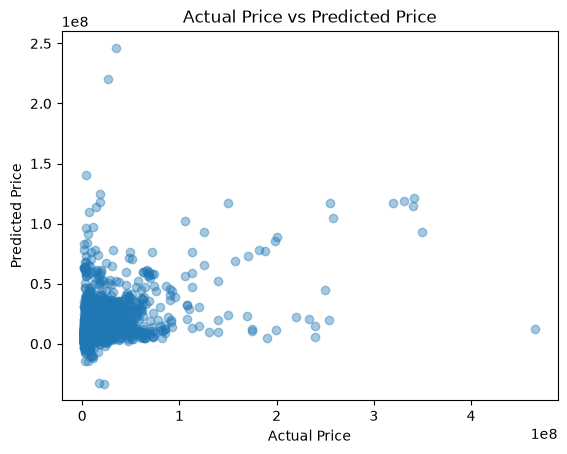

In [22]:
plt.scatter(y_test, best_predictions, alpha=0.4)
plt.title("Actual Price vs Predicted Price")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.show()

**Inference:** Points closer to the imagined diagonal line from bottom-left to top-right indicate more accurate predictions. Points far away indicate larger errors.

## Step 23: Inspect a few predictions

In [23]:
prediction_check = pd.DataFrame({
    "Actual Price": y_test.iloc[:10].values,
    "Predicted Price": best_predictions[:10]
})
prediction_check["Absolute Error"] = (
    prediction_check["Actual Price"] - prediction_check["Predicted Price"]
).abs()
print(prediction_check)

   Actual Price  Predicted Price  Absolute Error
0       8338000     1.203401e+07    3.696007e+06
1       8083000     1.118367e+07    3.100674e+06
2       4600000     9.976869e+06    5.376869e+06
3       5500000     6.809285e+06    1.309285e+06
4      17500000     1.036833e+07    7.131673e+06
5       3946000     9.431292e+06    5.485292e+06
6       3971000     3.213572e+06    7.574281e+05
7       5800000     8.342238e+06    2.542238e+06
8       4700000     9.627505e+06    4.927505e+06
9       9600000     1.191936e+07    2.319362e+06


**Inference:** This compares ten predictions with known prices. Use overall MAE, RMSE, and R² to judge the model rather than just these ten rows.

## Step 24: Save the model and results

In [24]:
joblib.dump(best_model, "best_house_price_model.joblib")
results.to_csv("model_evaluation_results.csv", index=False)
df.to_csv("cleaned_indian_house_prices.csv", index=False)

print("Saved best_house_price_model.joblib")
print("Saved model_evaluation_results.csv")
print("Saved cleaned_indian_house_prices.csv")

Saved best_house_price_model.joblib
Saved model_evaluation_results.csv
Saved cleaned_indian_house_prices.csv


**Inference:** The saved model includes the preprocessing steps and trained estimator. The CSV files keep the cleaned data and evaluation metrics.

## Step 25: Make an example prediction

In [25]:
new_house = X_test.iloc[[0]]
predicted_price = best_model.predict(new_house)[0]

print("House details:")
display(new_house)
print("Actual price:", y_test.iloc[0])
print("Predicted price:", predicted_price)

House details:


,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,RainWaterHarvesting,...,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Stadium,city
23030,650,Mira Road East,1,0,9,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,Mumbai


Actual price: 8338000
Predicted price: 12034006.522899024


**Inference:** This demonstrates a prediction for one test house. The model's overall scores are more informative than one example.

## Step 26: Final project summary

In [26]:
print("FINAL PROJECT SUMMARY")
print("---------------------")
print("Cleaned listings:", len(df))
print("Cities analysed:", df["city"].nunique())
print("Highest median-price city:", city_prices["median"].idxmax())
print("Lowest median-price city:", city_prices["median"].idxmin())
print("Best model:", best_name)
print("MAE:", results.iloc[0]["MAE"])
print("RMSE:", results.iloc[0]["RMSE"])
print("R2:", results.iloc[0]["R2"])

FINAL PROJECT SUMMARY
---------------------
Cleaned listings: 29135
Cities analysed: 6
Highest median-price city: Mumbai
Lowest median-price city: Kolkata
Best model: Linear Regression
MAE: 7574195.825088155
RMSE: 18680734.271509115
R2: 0.17564138692463205


**Final inference:** Use the actual values printed above to write your conclusion. Mention which city had the highest and lowest median prices, what the area-price plot showed, and which model had the lowest test RMSE.

**Files produced:** `cleaned_indian_house_prices.csv`, `model_evaluation_results.csv`, and `best_house_price_model.joblib`.